outputs/dataframe_errors.csv: (1, 13)  colonne = ['model', 'type', 'train-mse', 'val-mse', 'test-mse', 'train-mre', 'val-mre', 'test-mre', 'train-nrmse', 'val-nrmse', 'test-nrmse', 'train', 'inference']
outputs/dataframe_errors_cs.csv: (1, 7)  colonne = ['model', 'type', 'train-nrmse', 'val-nrmse', 'test-nrmse', 'train', 'inference']
ATTENZIONE colonne diverse: solo nel 1°: {'val-mse', 'test-mre', 'train-mse', 'test-mse', 'val-mre', 'train-mre'} | solo nel 2°: set()
righe dopo concat: 2


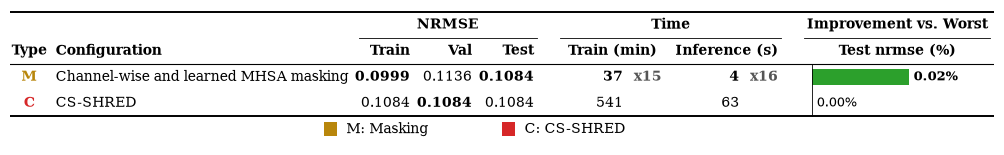

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
})

path = "outputs/dataframe_errors.csv"
path2 = "outputs/dataframe_errors_cs.csv"
df1 = pd.read_csv(path)
df2 = pd.read_csv(path2)
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# diagnostica: controlla che il secondo csv venga davvero letto
print(f"{path}: {df1.shape}  colonne = {list(df1.columns)}")
print(f"{path2}: {df2.shape}  colonne = {list(df2.columns)}")
if set(df1.columns) != set(df2.columns):
    print("ATTENZIONE colonne diverse:",
          "solo nel 1°:", set(df1.columns) - set(df2.columns),
          "| solo nel 2°:", set(df2.columns) - set(df1.columns))

df = (pd.concat([df1, df2], ignore_index=True, sort=False)
        .sort_values("test-nrmse").reset_index(drop=True))
print("righe dopo concat:", len(df))

num_cols = ["train-nrmse", "val-nrmse", "test-nrmse"]
time_cols = ["train", "inference"]          # colonne del csv per il tempo
best = df[num_cols + time_cols].min()

# ---- improvement vs worst model ----
worst_nrmse = df["test-nrmse"].max()
df["impr"] = (worst_nrmse - df["test-nrmse"]) / worst_nrmse * 100
best_impr = df["impr"].max()

# ---- improvement del tempo di training vs worst ----
for c in time_cols:                                  # gain: xN rispetto al più lento
    df[f"gain_{c}"] = df[c].max() / df[c]
best_gain = {c: df[f"gain_{c}"].max() for c in time_cols}

def fmt_gain(g):
    """x20, x4.5; vuoto se il gain è x1 (nessun miglioramento)."""
    s = f"x{g:.0f}" if g >= 10 else f"x{g:.1f}".replace(".0", "")
    return "" if s == "x1" else s

# ---- colori per gruppo (palette da paper) ----
C_BASE  = "#000000"   # nero   -> baselines
C_IMPUT = "#1F4E9C"   # blu    -> imputation
C_MASK  = "#B8860B"   # oro    -> masking
C_GRUD  = "#7F7F7F"   # grigio -> GRU-D
C_CSSHRED = "#D62728"   # rosso  -> CS-SHRED

GROUP_COLORS = {"0": C_BASE, "1": C_IMPUT, "2": C_GRUD, "3": C_MASK, "4": C_CSSHRED}
GROUP_LETTER = {"0": "B", "1": "I", "2": "G", "3": "M", "4": "C"}

# legenda: (lettera, nome, colore)
LEGEND = [
    ("M", "Masking",    C_MASK),
    ("C", "CS-SHRED",   C_CSSHRED)
]

# ---- rinomina etichette ----
RENAME = {
    # --- Masking (M) ---
    "masking x2 channels + MHSA learned":    "Channel-wise and learned MHSA masking",
    "masking hidden space":                  "Hidden-space masking",
    "masking x2 channels + MHSA":            "Channel-wise and MHSA masking",
    "masking":                               "Standard masking",
    "masking MHSA":                          "MHSA masking",
    "masking MHSA learned":                  "Learned MHSA masking",
    "masking x2 channels":                   "Channel-wise masking",

    # --- Imputation (I) ---
    "last-value imputation for missing sensors": "LOCF + T-SHRED",
    "LOCF for missing sensors":                  "LOCF + T-SHRED",
    "median imputation for missing sensors":     "Median imputation + T-SHRED",
    "mean imputation for missing sensors":       "Mean imputation + T-SHRED",

    # --- GRU-D (G) ---
    "GRUD":                                  "GRUD",        # TODO
    "Attn-GRUD":                             "Attn-GRUD",   # TODO

    # --- Baselines (B) ---
    "always-available stations only":             "Always-available sensors + SHRED",
    "always-available stations only transformer": "Always-available sensors + T-SHRED",

    "CSSHRED": "CS-SHRED",
}

def _norm(s):
    """Minuscolo, spazi multipli ridotti a uno, bordi puliti."""
    return re.sub(r"\s+", " ", s).strip().lower()

RENAME_NORM = {_norm(k): v for k, v in RENAME.items()}

def rename_rest(s):
    body = s.lstrip(": ").strip()
    key = _norm(body)
    if key not in RENAME_NORM:
        print("NO MATCH:", repr(body))   # utile per aggiungere le chiavi mancanti
    return RENAME_NORM.get(key, body)

TAG_RE = re.compile(r"^\(([A-Za-z])\.(\d)(?:\.([A-Za-z0-9]+))?\)(.*)$")

def parse_label(text):
    """Ritorna (lettera, testo, colore)."""
    m = TAG_RE.match(text)
    if not m:
        return "", text, "black"
    _, group, _, rest = m.groups()
    return GROUP_LETTER.get(group, "?"), rename_rest(rest), GROUP_COLORS.get(group, "black")

# ---- font ----
fs = 10                                # dimensione base del testo
fs_small = fs - 1                      # etichette % delle barre

# ---- layout (widths in inches) ----
# colonne: 0 Type | 1 Configuration | 2-4 NRMSE | 5 gap
#          | 6 Train time | 7 % impr. train (senza titolo) | 8 Inference | 9 gap | 10 barre
type_col_w = 0.5
first_col_w = 3.95
num_col_w = 0.8
train_col_w = 0.95
inf_col_w = 1.0
gain_col_w = 0.5
bar_col_w = 2.5
gap_w = 0.2                 # spazio tra i gruppi

widths = ([type_col_w, first_col_w]
          + [num_col_w] * 3 + [gap_w]
          + [train_col_w, gain_col_w, inf_col_w, gain_col_w] + [gap_w]
          + [bar_col_w])
xs = [sum(widths[:i]) for i in range(len(widths))]
total_w = sum(widths)

NRMSE_COLS = [2, 3, 4]
TIME_COLS = [6, 8]            # train, inference
                              # a destra di ogni colonna tempo (col+1) c'è il gain xN, senza titolo
BAR = len(widths) - 1

row_h = 0.32
n_rows = len(df)
header_rows = 2
legend_rows = 1.0
fig_h = (n_rows + header_rows + legend_rows + 0.2) * row_h + 0.1

fig, ax = plt.subplots(figsize=(total_w, fig_h))
ax.set_xlim(0, total_w)
ax.set_ylim(n_rows + header_rows + legend_rows + 0.1, -0.1)
ax.axis("off")

pad = 0.09

def put(col, row, text, ha="left", **kw):
    if ha == "left":
        x = xs[col] + pad
    elif ha == "right":
        x = xs[col] + widths[col] - pad
    else:
        x = xs[col] + widths[col] / 2
    ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=fs, **kw)

# ---- header ----
ax.text(xs[2] + sum(widths[2:5]) / 2, 0.5, "NRMSE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[6] + sum(widths[6:10]) / 2, 0.5, "Time", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[BAR] + widths[BAR] / 2, 0.5, "Improvement vs. Worst", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.plot([xs[2] + 0.05, xs[5] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[6] + 0.05, xs[10] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[BAR] + 0.05, total_w - 0.05], [1, 1], color="black", lw=0.6)

put(0, 1, "Type", ha="center", fontweight="bold")
put(1, 1, "Configuration", fontweight="bold")
for col, name in zip(NRMSE_COLS, ["Train", "Val", "Test"]):
    put(col, 1, name, ha="right", fontweight="bold")
for col, name in zip(TIME_COLS, ["Train (min)", "Inference (s)"]):
    # centrato sulla doppia colonna: valore + gain (col, col+1)
    ax.text(xs[col] + (widths[col] + widths[col + 1]) / 2, 1.5, name,
            ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[BAR] + widths[BAR] / 2, 1.5, "Test nrmse (%)", ha="center", va="center", fontsize=fs, fontweight="bold")

# ---- bar scale ----
label_w = 1.0
bx0 = xs[BAR] + 0.15
usable = widths[BAR] - 0.15 - label_w - 0.1
vmin = min(df["impr"].min(), 0.0)
vmax = max(df["impr"].max(), 1e-9)
scale = usable / (vmax - vmin)
zero_x = bx0 + (-vmin) * scale
bar_h = 0.62

# ---- body ----
for r, row in df.iterrows():
    y = r + header_rows
    letter, rest, color = parse_label(row["type"])
    put(0, y, letter, ha="center", color=color, fontweight="bold")
    put(1, y, rest)
    for col, c in zip(NRMSE_COLS, num_cols):
        is_best = row[c] == best[c]
        put(col, y, f"{row[c]:.4f}", ha="right", fontweight="bold" if is_best else "normal")
    for col, c in zip(TIME_COLS, time_cols):
        is_best = row[c] == best[c]
        put(col, y, f"{row[c]:.0f}", ha="right", fontweight="bold" if is_best else "normal")
        g = row[f"gain_{c}"]
        put(col + 1, y, fmt_gain(g), ha="right", color="#555555",
            fontweight="bold" if np.isclose(g, best_gain[c]) else "normal")

    v = row["impr"]
    w = v * scale
    ax.add_patch(Rectangle((zero_x if v >= 0 else zero_x + w, y + (1 - bar_h) / 2),
                           abs(w), bar_h, facecolor="#2ca02c", edgecolor="none"))

    weight = "bold" if np.isclose(v, best_impr) else "normal"
    if v >= 0:
        ax.text(zero_x + w + 0.06, y + 0.5, f"{v:.2f}%", ha="left", va="center",
                fontsize=fs_small, fontweight=weight)
    else:
        ax.text(zero_x + w - 0.06, y + 0.5, f"{v:.2f}%", ha="right", va="center",
                fontsize=fs_small, fontweight=weight)

ax.plot([zero_x, zero_x], [header_rows, n_rows + header_rows], color="black", lw=0.6)

# ---- three booktabs rules ----
ax.plot([0, total_w], [0, 0], color="black", lw=1.4)
ax.plot([0, total_w], [header_rows, header_rows], color="black", lw=0.8)
ax.plot([0, total_w], [n_rows + header_rows, n_rows + header_rows], color="black", lw=1.4)

# ---- legenda sotto la tabella ----
ly = n_rows + header_rows + legend_rows / 2
sq = 0.17
sq_h = sq / row_h
gap_marker_text = 0.12
entry_w = 2.3
x_start = (total_w - entry_w * len(LEGEND)) / 2

for i, (letter, label, color) in enumerate(LEGEND):
    x = x_start + i * entry_w
    ax.add_patch(Rectangle((x, ly - sq_h / 2), sq, sq_h, facecolor=color, edgecolor="none"))
    ax.text(x + sq + gap_marker_text, ly, f"{letter}: {label}", ha="left", va="center", fontsize=fs)

fig.savefig("SST_3_table.png", dpi=500, bbox_inches="tight", pad_inches=0.03)
fig.savefig("SST_3_table.pdf", bbox_inches="tight", pad_inches=0.03)   # vettoriale per il paper
plt.show()

outputs/dataframe_errors.csv: (1, 13)  colonne = ['model', 'type', 'train-mse', 'val-mse', 'test-mse', 'train-mre', 'val-mre', 'test-mre', 'train-nrmse', 'val-nrmse', 'test-nrmse', 'train', 'inference']
outputs/dataframe_errors_cs.csv: (1, 7)  colonne = ['model', 'type', 'train-nrmse', 'val-nrmse', 'test-nrmse', 'train', 'inference']
ATTENZIONE colonne diverse: solo nel 1°: {'test-mre', 'train-mse', 'val-mre', 'train-mre', 'test-mse', 'val-mse'} | solo nel 2°: set()
righe dopo concat: 2


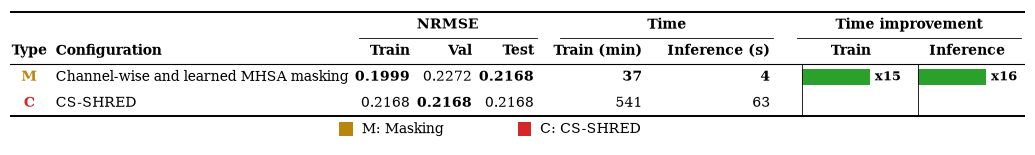

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "pdf.fonttype": 42,
})

path = "outputs/dataframe_errors.csv"
path2 = "outputs/dataframe_errors_cs.csv"

df1 = pd.read_csv(path)
df2 = pd.read_csv(path2)

# moltiplica x2 tutte le colonne nrmse
nrmse_cols = ["train-nrmse", "val-nrmse", "test-nrmse"]
df1[nrmse_cols] *= 2
df2[nrmse_cols] *= 2

df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()

# diagnostica: controlla che il secondo csv venga davvero letto
print(f"{path}: {df1.shape}  colonne = {list(df1.columns)}")
print(f"{path2}: {df2.shape}  colonne = {list(df2.columns)}")
if set(df1.columns) != set(df2.columns):
    print("ATTENZIONE colonne diverse:",
          "solo nel 1°:", set(df1.columns) - set(df2.columns),
          "| solo nel 2°:", set(df2.columns) - set(df1.columns))

df = (pd.concat([df1, df2], ignore_index=True, sort=False)
        .sort_values("test-nrmse").reset_index(drop=True))
print("righe dopo concat:", len(df))

num_cols = ["train-nrmse", "val-nrmse", "test-nrmse"]
time_cols = ["train", "inference"]          # colonne del csv per il tempo
best = df[num_cols + time_cols].min()

# ---- time improvement vs worst (train e inference) ----
for c in time_cols:                                  # gain: xN rispetto al più lento
    df[f"gain_{c}"] = df[c].max() / df[c]
best_gain = {c: df[f"gain_{c}"].max() for c in time_cols}

def fmt_gain(g):
    """x20, x4.5; vuoto se il gain è x1 (nessun miglioramento)."""
    s = f"x{g:.0f}" if g >= 10 else f"x{g:.1f}".replace(".0", "")
    return "" if s == "x1" else s

# ---- colori per gruppo (palette da paper) ----
C_BASE  = "#000000"   # nero   -> baselines
C_IMPUT = "#1F4E9C"   # blu    -> imputation
C_MASK  = "#B8860B"   # oro    -> masking
C_GRUD  = "#7F7F7F"   # grigio -> GRU-D
C_CSSHRED = "#D62728"   # rosso  -> CS-SHRED

GROUP_COLORS = {"0": C_BASE, "1": C_IMPUT, "2": C_GRUD, "3": C_MASK, "4": C_CSSHRED}
GROUP_LETTER = {"0": "B", "1": "I", "2": "G", "3": "M", "4": "C"}

# legenda: (lettera, nome, colore)
LEGEND = [
    ("M", "Masking",    C_MASK),
    ("C", "CS-SHRED",   C_CSSHRED)
]

# ---- rinomina etichette ----
RENAME = {
    # --- Masking (M) ---
    "masking x2 channels + MHSA learned":    "Channel-wise and learned MHSA masking",
    "masking hidden space":                  "Hidden-space masking",
    "masking x2 channels + MHSA":            "Channel-wise and MHSA masking",
    "masking":                               "Standard masking",
    "masking MHSA":                          "MHSA masking",
    "masking MHSA learned":                  "Learned MHSA masking",
    "masking x2 channels":                   "Channel-wise masking",

    # --- Imputation (I) ---
    "last-value imputation for missing sensors": "LOCF + T-SHRED",
    "LOCF for missing sensors":                  "LOCF + T-SHRED",
    "median imputation for missing sensors":     "Median imputation + T-SHRED",
    "mean imputation for missing sensors":       "Mean imputation + T-SHRED",

    # --- GRU-D (G) ---
    "GRUD":                                  "GRUD",        # TODO
    "Attn-GRUD":                             "Attn-GRUD",   # TODO

    # --- Baselines (B) ---
    "always-available stations only":             "Always-available sensors + SHRED",
    "always-available stations only transformer": "Always-available sensors + T-SHRED",

    "CSSHRED": "CS-SHRED",
}

def _norm(s):
    """Minuscolo, spazi multipli ridotti a uno, bordi puliti."""
    return re.sub(r"\s+", " ", s).strip().lower()

RENAME_NORM = {_norm(k): v for k, v in RENAME.items()}

def rename_rest(s):
    body = s.lstrip(": ").strip()
    key = _norm(body)
    if key not in RENAME_NORM:
        print("NO MATCH:", repr(body))   # utile per aggiungere le chiavi mancanti
    return RENAME_NORM.get(key, body)

TAG_RE = re.compile(r"^\(([A-Za-z])\.(\d)(?:\.([A-Za-z0-9]+))?\)(.*)$")

def parse_label(text):
    """Ritorna (lettera, testo, colore)."""
    m = TAG_RE.match(text)
    if not m:
        return "", text, "black"
    _, group, _, rest = m.groups()
    return GROUP_LETTER.get(group, "?"), rename_rest(rest), GROUP_COLORS.get(group, "black")

# ---- font ----
fs = 10                                # dimensione base del testo
fs_small = fs - 1                      # etichette % delle barre

# ---- layout (widths in inches) ----
# colonne: 0 Type | 1 Configuration | 2-4 NRMSE | 5 gap | 6 Train time | 7 Inference time
#          | 8 gap | 9 barre gain train | 10 barre gain inference
type_col_w = 0.5
first_col_w = 3.95
num_col_w = 0.8
train_col_w = 1.2
inf_col_w = 1.65
bar_col_w = 1.5
gap_w = 0.2                 # spazio tra i gruppi

widths = ([type_col_w, first_col_w]
          + [num_col_w] * 3 + [gap_w]
          + [train_col_w, inf_col_w] + [gap_w]
          + [bar_col_w] * 2)
xs = [sum(widths[:i]) for i in range(len(widths))]
total_w = sum(widths)

NRMSE_COLS = [2, 3, 4]
TIME_COLS = [6, 7]            # train, inference
BAR_COLS = [9, 10]            # time improvement (xN): train, inference

row_h = 0.32
n_rows = len(df)
header_rows = 2
legend_rows = 1.0
fig_h = (n_rows + header_rows + legend_rows + 0.2) * row_h + 0.1

fig, ax = plt.subplots(figsize=(total_w, fig_h))
ax.set_xlim(0, total_w)
ax.set_ylim(n_rows + header_rows + legend_rows + 0.1, -0.1)
ax.axis("off")

pad = 0.09

def put(col, row, text, ha="left", **kw):
    if ha == "left":
        x = xs[col] + pad
    elif ha == "right":
        x = xs[col] + widths[col] - pad
    else:
        x = xs[col] + widths[col] / 2
    ax.text(x, row + 0.5, text, ha=ha, va="center", fontsize=fs, **kw)

# ---- header ----
ax.text(xs[2] + sum(widths[2:5]) / 2, 0.5, "NRMSE", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[6] + sum(widths[6:8]) / 2, 0.5, "Time", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.text(xs[9] + sum(widths[9:11]) / 2, 0.5, "Time improvement", ha="center", va="center", fontsize=fs, fontweight="bold")
ax.plot([xs[2] + 0.05, xs[5] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[6] + 0.05, xs[8] - 0.05], [1, 1], color="black", lw=0.6)
ax.plot([xs[9] + 0.05, total_w - 0.05], [1, 1], color="black", lw=0.6)

put(0, 1, "Type", ha="center", fontweight="bold")
put(1, 1, "Configuration", fontweight="bold")
for col, name in zip(NRMSE_COLS, ["Train", "Val", "Test"]):
    put(col, 1, name, ha="right", fontweight="bold")
for col, name in zip(TIME_COLS, ["Train (min)", "Inference (s)"]):
    put(col, 1, name, ha="right", fontweight="bold")
for col, name in zip(BAR_COLS, ["Train", "Inference"]):
    put(col, 1, name, ha="center", fontweight="bold")

# ---- bar scale (una per colonna: la barra è proporzionale al gain xN) ----
label_w = 0.45
bar_h = 0.62
bar_x0 = {}      # x dello zero di ogni colonna barre
bar_scale = {}   # pollici per unità di gain
for bcol, c in zip(BAR_COLS, time_cols):
    bar_x0[c] = xs[bcol] + 0.12
    usable = widths[bcol] - 0.12 - label_w - 0.05
    bar_scale[c] = usable / best_gain[c]

# ---- body ----
for r, row in df.iterrows():
    y = r + header_rows
    letter, rest, color = parse_label(row["type"])
    put(0, y, letter, ha="center", color=color, fontweight="bold")
    put(1, y, rest)
    for col, c in zip(NRMSE_COLS, num_cols):
        is_best = row[c] == best[c]
        put(col, y, f"{row[c]:.4f}", ha="right", fontweight="bold" if is_best else "normal")
    for col, c in zip(TIME_COLS, time_cols):
        is_best = row[c] == best[c]
        put(col, y, f"{row[c]:.0f}", ha="right", fontweight="bold" if is_best else "normal")

    for c in time_cols:
        g = row[f"gain_{c}"]
        w = g * bar_scale[c]
        label = fmt_gain(g)           # vuoto se x1 (nessun improvement)
        if label:                     # barra e etichetta solo se c'è improvement
            ax.add_patch(Rectangle((bar_x0[c], y + (1 - bar_h) / 2), w, bar_h,
                                   facecolor="#2ca02c", edgecolor="none"))
            ax.text(bar_x0[c] + w + 0.06, y + 0.5, label, ha="left", va="center",
                    fontsize=fs_small,
                    fontweight="bold" if np.isclose(g, best_gain[c]) else "normal")

for c in time_cols:
    ax.plot([bar_x0[c], bar_x0[c]], [header_rows, n_rows + header_rows], color="black", lw=0.6)

# ---- three booktabs rules ----
ax.plot([0, total_w], [0, 0], color="black", lw=1.4)
ax.plot([0, total_w], [header_rows, header_rows], color="black", lw=0.8)
ax.plot([0, total_w], [n_rows + header_rows, n_rows + header_rows], color="black", lw=1.4)

# ---- legenda sotto la tabella ----
ly = n_rows + header_rows + legend_rows / 2
sq = 0.17
sq_h = sq / row_h
gap_marker_text = 0.12
entry_w = 2.3
x_start = (total_w - entry_w * len(LEGEND)) / 2

for i, (letter, label, color) in enumerate(LEGEND):
    x = x_start + i * entry_w
    ax.add_patch(Rectangle((x, ly - sq_h / 2), sq, sq_h, facecolor=color, edgecolor="none"))
    ax.text(x + sq + gap_marker_text, ly, f"{letter}: {label}", ha="left", va="center", fontsize=fs)

fig.savefig("SST_3_table.png", dpi=500, bbox_inches="tight", pad_inches=0.03)
fig.savefig("SST_3_table.pdf", bbox_inches="tight", pad_inches=0.03)   # vettoriale per il paper
plt.show()